# Importing Libraries

In [70]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cluster import DBSCAN, KMeans
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler


import warnings
warnings.filterwarnings('ignore')

# Initial Data inspection

### Encoding check

In [37]:
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "archive"

file_paths = {
    "General": DATA_DIR / "general_data.csv",
    "Employee": DATA_DIR / "employee_survey_data.csv",
    "Manager": DATA_DIR / "manager_survey_data.csv",
    "In-time": DATA_DIR / "in_time.csv",
    "Out-time": DATA_DIR / "out_time.csv"
}

for name, path in file_paths.items():
    try:
        pd.read_csv(path, encoding="utf-8")
        print(f"{name}: UTF-8")
    except UnicodeDecodeError:
        print(f"{name}: Not UTF-8")

General: UTF-8
Employee: UTF-8
Manager: UTF-8
In-time: UTF-8
Out-time: UTF-8


### Data inspection

In [38]:
df_general = pd.read_csv(DATA_DIR / "general_data.csv")
df_employee = pd.read_csv(DATA_DIR / "employee_survey_data.csv")
df_manager = pd.read_csv(DATA_DIR / "manager_survey_data.csv")
df_inTime = pd.read_csv(DATA_DIR / "in_time.csv")
df_outTime = pd.read_csv(DATA_DIR / "out_time.csv")

In [39]:
# General
df_general.info()

df_general.describe(include='all')

print(df_general.isnull().sum())

df_general.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   str    
 2   BusinessTravel           4410 non-null   str    
 3   Department               4410 non-null   str    
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   str    
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   str    
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   str    
 12  MaritalStatus            4410 non-null   str    
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked       4391 non-n

np.int64(0)

In [40]:
# Employee
df_employee.info()

df_employee.describe(include='all')

print(df_employee.isnull().sum())

df_employee.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   EmployeeID               4410 non-null   int64  
 1   EnvironmentSatisfaction  4385 non-null   float64
 2   JobSatisfaction          4390 non-null   float64
 3   WorkLifeBalance          4372 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 137.9 KB
EmployeeID                  0
EnvironmentSatisfaction    25
JobSatisfaction            20
WorkLifeBalance            38
dtype: int64


np.int64(0)

In [41]:
# Manager
df_manager.info()

df_manager.describe(include='all')

print(df_manager.isnull().sum())

df_manager.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   EmployeeID         4410 non-null   int64
 1   JobInvolvement     4410 non-null   int64
 2   PerformanceRating  4410 non-null   int64
dtypes: int64(3)
memory usage: 103.5 KB
EmployeeID           0
JobInvolvement       0
PerformanceRating    0
dtype: int64


np.int64(0)

In [42]:
# In-time
df_inTime.info()

df_inTime.describe(include='all')

missing_values = df_inTime.isnull().sum()

print("Total missing values:", missing_values.sum())

print("Number of duplicate rows:", df_inTime.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, Unnamed: 0 to 2015-12-31
dtypes: float64(12), int64(1), str(249)
memory usage: 8.8 MB
Total missing values: 109080
Number of duplicate rows: 0


In [43]:
# Out time
df_outTime.info()

df_outTime.describe(include='all')

missing_values = df_outTime.isnull().sum()
print("Total missing values:", missing_values.sum())

print("Number of duplicate rows:", df_outTime.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, Unnamed: 0 to 2015-12-31
dtypes: float64(12), int64(1), str(249)
memory usage: 8.8 MB
Total missing values: 109080
Number of duplicate rows: 0


 ### Identify relationships

In [44]:
datasets = {
    "General": df_general,
    "Employee": df_employee,
    "Manager": df_manager,
    "In-time": df_inTime,
    "Out-time": df_outTime
}

dataset_names = list(datasets.keys())

for i in range(len(dataset_names)):
    for j in range(i + 1, len(dataset_names)):

        name1 = dataset_names[i]
        name2 = dataset_names[j]

        common_columns = set(datasets[name1].columns) & set(datasets[name2].columns)

        print(f"{name1} - {name2}: {common_columns}")

General - Employee: {'EmployeeID'}
General - Manager: {'EmployeeID'}
General - In-time: set()
General - Out-time: set()
Employee - Manager: {'EmployeeID'}
Employee - In-time: set()
Employee - Out-time: set()
Manager - In-time: set()
Manager - Out-time: set()
In-time - Out-time: {'2015-12-10', '2015-12-21', '2015-12-14', '2015-06-15', '2015-08-18', '2015-04-15', '2015-05-13', '2015-12-15', '2015-11-10', '2015-08-13', '2015-02-12', '2015-03-23', '2015-10-13', '2015-07-31', '2015-06-18', '2015-11-02', '2015-01-27', '2015-10-20', '2015-02-23', '2015-11-11', '2015-01-01', '2015-09-29', '2015-01-19', '2015-02-13', '2015-08-19', '2015-09-14', '2015-07-20', '2015-12-25', '2015-09-30', '2015-06-17', '2015-06-12', '2015-11-23', '2015-06-23', '2015-11-17', '2015-08-28', '2015-02-03', '2015-03-02', '2015-12-04', '2015-07-23', '2015-03-17', '2015-02-04', '2015-03-18', '2015-01-06', '2015-07-15', '2015-02-09', '2015-06-16', '2015-09-07', '2015-05-19', '2015-11-26', '2015-06-22', '2015-11-25', '2015-

## Data Loading and Integration

In [45]:
df_final = df_general.merge(df_employee, on='EmployeeID').merge(df_manager, on='EmployeeID')

In [46]:
df_final.head() # a dataframe containing complete information for each employee

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating
0,51,No,Travel_Rarely,Sales,6,2,Life Sciences,1,1,Female,...,1.0,6,1,0,0,3.0,4.0,2.0,3,3
1,31,Yes,Travel_Frequently,Research & Development,10,1,Life Sciences,1,2,Female,...,6.0,3,5,1,4,3.0,2.0,4.0,2,4
2,32,No,Travel_Frequently,Research & Development,17,4,Other,1,3,Male,...,5.0,2,5,0,3,2.0,2.0,1.0,3,3
3,38,No,Non-Travel,Research & Development,2,5,Life Sciences,1,4,Male,...,13.0,5,8,7,5,4.0,4.0,3.0,2,3
4,32,No,Travel_Rarely,Research & Development,10,1,Medical,1,5,Male,...,9.0,2,6,0,4,4.0,1.0,3.0,3,3


In [47]:
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   str    
 2   BusinessTravel           4410 non-null   str    
 3   Department               4410 non-null   str    
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   str    
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   str    
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   str    
 12  MaritalStatus            4410 non-null   str    
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked       4391 non-n

# Data Cleaning

In [48]:
df = df_final.copy()

### Missing values check

In [49]:
print(df.isnull().sum())

Age                         0
Attrition                   0
BusinessTravel              0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeID                  0
Gender                      0
JobLevel                    0
JobRole                     0
MaritalStatus               0
MonthlyIncome               0
NumCompaniesWorked         19
Over18                      0
PercentSalaryHike           0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           9
TrainingTimesLastYear       0
YearsAtCompany              0
YearsSinceLastPromotion     0
YearsWithCurrManager        0
EnvironmentSatisfaction    25
JobSatisfaction            20
WorkLifeBalance            38
JobInvolvement              0
PerformanceRating           0
dtype: int64


In [50]:
print(df.duplicated().sum())
print(df['EmployeeID'].duplicated().sum())

0
0


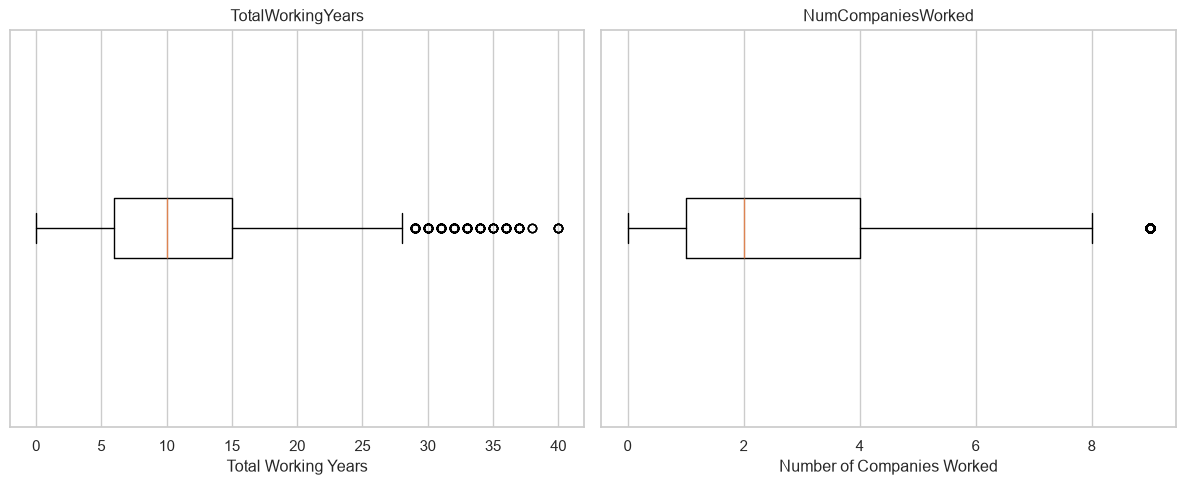

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(
    df['TotalWorkingYears'].dropna(),
    vert=False
)
axes[0].set_title('TotalWorkingYears')
axes[0].set_xlabel('Total Working Years')
axes[0].get_yaxis().set_visible(False)


axes[1].boxplot(
    df['NumCompaniesWorked'].dropna(),
    vert=False
)
axes[1].set_title('NumCompaniesWorked')
axes[1].set_xlabel('Number of Companies Worked')
axes[1].get_yaxis().set_visible(False)

plt.tight_layout()

plt.savefig(
    'latex_report/src/figures/figure1.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

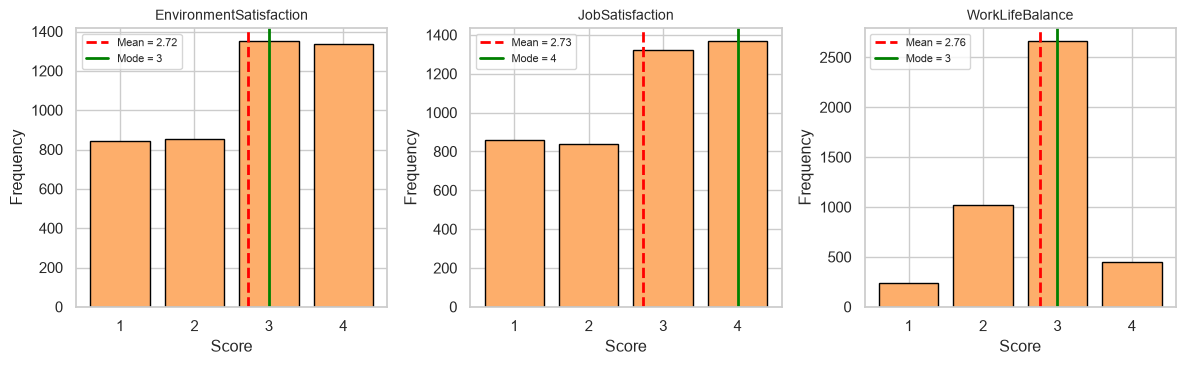

In [52]:
ORD_COLS = [
    'EnvironmentSatisfaction',
    'JobSatisfaction',
    'WorkLifeBalance'
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

for ax, col in zip(axes, ORD_COLS):

    data = df_employee[col].dropna()
    counts = data.value_counts().sort_index()

    ax.bar(
        counts.index.astype(int),
        counts.values,
        color="#fdae6b",
        edgecolor="black"
    )

    mean_value = data.mean()
    mode_value = data.mode().iloc[0]

    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean_value:.2f}"
    )

    ax.axvline(
        mode_value,
        color="green",
        linewidth=2,
        label=f"Mode = {int(mode_value)}"
    )

    ax.set_xticks([1, 2, 3, 4])
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Score")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

fig.tight_layout()

plt.savefig(
    'latex_report/src/figures/figure2.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Handle missing values

In [53]:
for col in ["NumCompaniesWorked", "TotalWorkingYears"]:
    df[col] = df[col].fillna(df[col].median())

for col in ["EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance"]:
    df[col] = df[col].fillna(df[col].mode()[0])


### Data types and constant columns

In [54]:
int_cols = ["NumCompaniesWorked", "TotalWorkingYears",
            "EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance"]
df[int_cols] = df[int_cols].astype(int)

df["Attrition"] = df["Attrition"].map({"Yes": 1, "No": 0}).astype(int)

cat_cols = ["BusinessTravel", "Department", "EducationField",
            "Gender", "JobRole", "MaritalStatus"]
df[cat_cols] = df[cat_cols].astype("category")

# remove columns with constant features
const_cols = [c for c in df.columns if df[c].nunique() == 1]
df = df.drop(columns=const_cols)

### Preparing attendance data

In [55]:
def prepare_time_df(df):
    df = df.rename(columns={'Unnamed: 0': 'EmployeeID'}).set_index('EmployeeID')
    return df.apply(pd.to_datetime, errors='coerce')

in_dt = prepare_time_df(df_inTime)
out_dt = prepare_time_df(df_outTime)
assert in_dt.shape == out_dt.shape and (in_dt.columns == out_dt.columns).all()

# holiday - no one in and out
holiday = in_dt.columns[in_dt.isna().all() & out_dt.isna().all()]
in_dt, out_dt = in_dt.drop(columns=holiday), out_dt.drop(columns=holiday)

# keep days with in and out
half = in_dt.isna() ^ out_dt.isna()
in_dt, out_dt = in_dt.mask(half), out_dt.mask(half)

# Valid duration: 0 < hours <= 24
hours = (out_dt - in_dt).apply(lambda s: s.dt.total_seconds() / 3600)
hours = hours.mask((hours <= 0) | (hours > 24))

# Aggregate per employee (absent days are skipped, not filled)
n_work = hours.shape[1]
att = pd.DataFrame({
    "AvgWorkHours": hours.mean(axis=1),
    "AbsentDays":   hours.isna().sum(axis=1),
})
att["AbsentRate"] = att["AbsentDays"] / n_work

# Employees with no valid day at all -> median
att["AvgWorkHours"] = att["AvgWorkHours"].fillna(att["AvgWorkHours"].median())
att = att.reset_index()

df_clean = df.merge(att, on="EmployeeID", how="left", validate="one_to_one")
df_clean = df_clean.reset_index(drop=True)

# Final check
assert df_clean.isnull().sum().sum() == 0
assert df_clean["EmployeeID"].is_unique

df_clean.head()

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeID,Gender,JobLevel,...,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating,AvgWorkHours,AbsentDays,AbsentRate
0,51,0,Travel_Rarely,Sales,6,2,Life Sciences,1,Female,1,...,0,0,3,4,2,3,3,7.373651,17,0.068273
1,31,1,Travel_Frequently,Research & Development,10,1,Life Sciences,2,Female,1,...,1,4,3,2,4,2,4,7.718969,13,0.052209
2,32,0,Travel_Frequently,Research & Development,17,4,Other,3,Male,4,...,0,3,2,2,1,3,3,7.013240,7,0.028112
3,38,0,Non-Travel,Research & Development,2,5,Life Sciences,4,Male,3,...,7,5,4,4,3,2,3,7.193678,14,0.056225
4,32,0,Travel_Rarely,Research & Development,10,1,Medical,5,Male,1,...,0,4,4,1,3,3,3,8.006175,4,0.016064


In [56]:
attendance_features = [
    "AvgWorkHours",
    "AbsentDays",
    "AbsentRate"
]

summary_att = pd.DataFrame({
    "Mean": att[attendance_features].mean(),
    "Std": att[attendance_features].std(),
    "Min": att[attendance_features].min(),
    "Median": att[attendance_features].median(),
    "Max": att[attendance_features].max()
})

summary_att = summary_att.round(2)

print(summary_att)

               Mean   Std   Min  Median    Max
AvgWorkHours   7.70  1.34  5.95    7.41  11.03
AbsentDays    12.73  5.50  1.00   13.00  24.00
AbsentRate     0.05  0.02  0.00    0.05   0.10


# EDA

In [57]:
RANDOM_STATE = 42
FIG_DIR = Path("latex_report/src/figures")
FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=0.95)

df = df_clean.set_index("EmployeeID").copy()


def save(fig, name):
    if fig.get_layout_engine() is None:      # skip when constrained layout is used
        fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()

### DISTRIBUTIONS AND CORRELATION

#### Demographic / seniority / income / distance / workload

                       mean       std       min       50%        max  skew
Age                   36.92      9.13     18.00     36.00      60.00  0.41
MonthlyIncome      65029.31  47068.89  10090.00  49190.00  199990.00  1.37
TotalWorkingYears     11.28      7.77      0.00     10.00      40.00  1.12
YearsAtCompany         7.01      6.13      0.00      5.00      40.00  1.76
DistanceFromHome       9.19      8.11      1.00      7.00      29.00  0.96
AvgWorkHours           7.70      1.34      5.95      7.41      11.03  0.86 



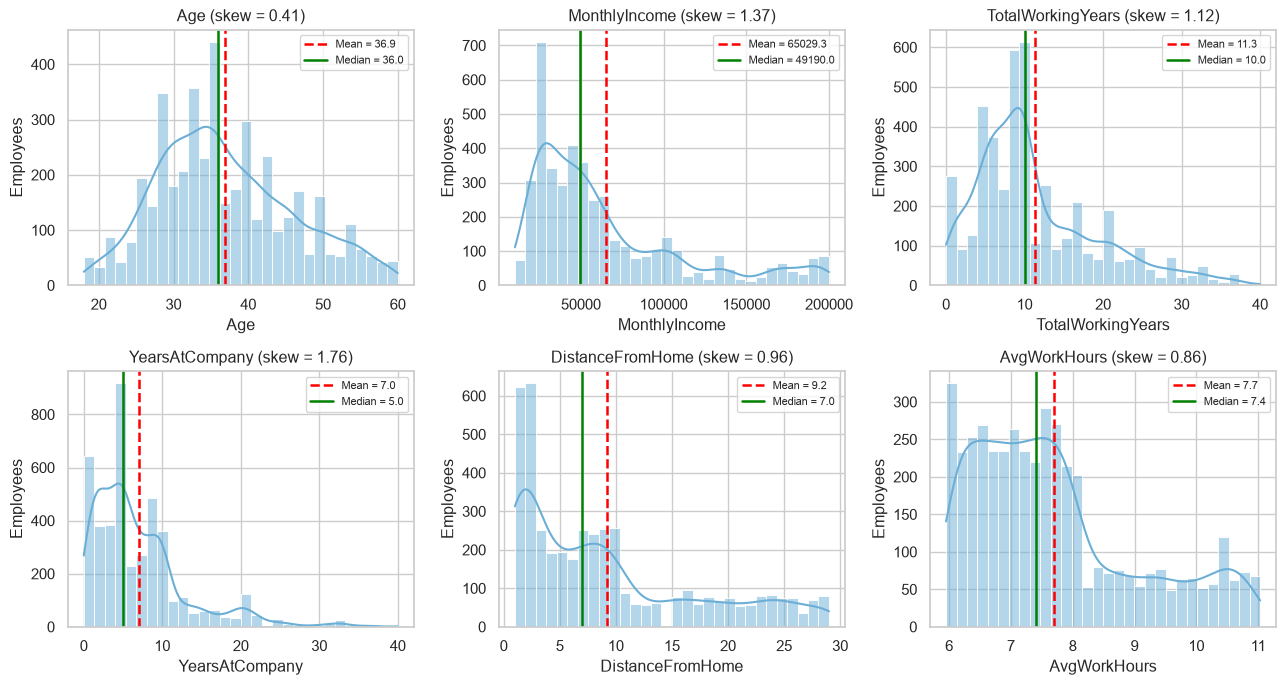

In [58]:
DIST_COLS = ["Age", "MonthlyIncome", "TotalWorkingYears",
             "YearsAtCompany", "DistanceFromHome", "AvgWorkHours"]

summary = df[DIST_COLS].describe().T[["mean", "std", "min", "50%", "max"]]
summary["skew"] = df[DIST_COLS].skew()
print(summary.round(2), "\n")

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), DIST_COLS):
    s = df[col]
    sns.histplot(s, bins=30, kde=True, color="#6baed6", edgecolor="white", ax=ax)
    ax.axvline(s.mean(), color="red", ls="--", lw=1.8, label=f"Mean = {s.mean():.1f}")
    ax.axvline(s.median(), color="green", lw=1.8, label=f"Median = {s.median():.1f}")
    ax.set_title(f"{col} (skew = {s.skew():.2f})")
    ax.set_ylabel("Employees")
    ax.legend(fontsize=8)
save(fig, "eda_dist.png")

#### Box plots (outlier view, each variable on its own scale

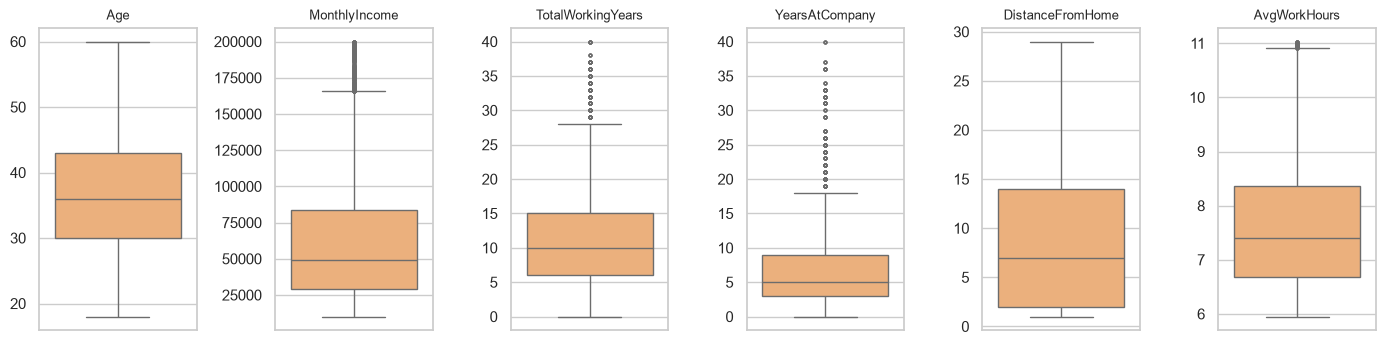

In [59]:
fig, axes = plt.subplots(1, len(DIST_COLS), figsize=(14, 3.6))
for ax, col in zip(axes, DIST_COLS):
    sns.boxplot(y=df[col], color="#fdae6b", fliersize=2, ax=ax)
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
save(fig, "eda_boxplot.png")

#### Survey variables

   EnvironmentSatisfaction  JobSatisfaction  WorkLifeBalance  JobInvolvement
1                     19.2             19.5              5.4             5.6
2                     19.4             19.0             23.1            25.5
3                     31.2             30.0             61.2            59.0
4                     30.2             31.5             10.3             9.8 



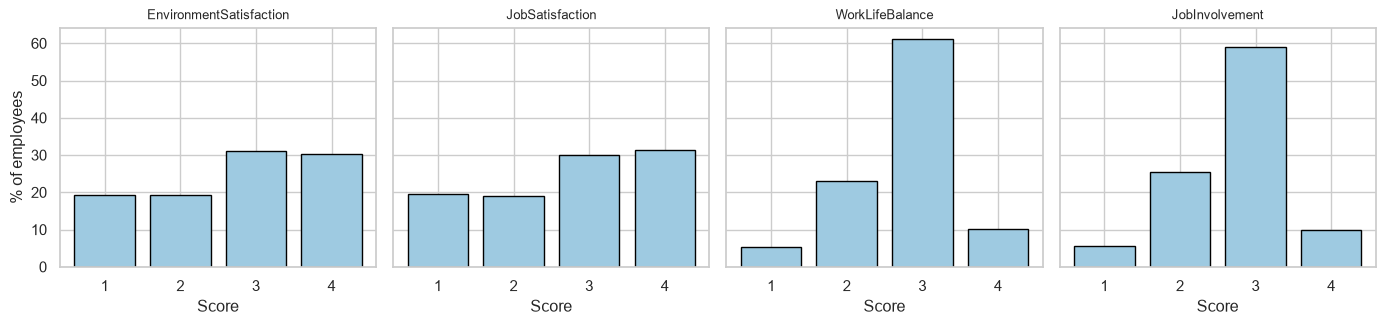

In [60]:
SURVEY = ["EnvironmentSatisfaction", "JobSatisfaction",
          "WorkLifeBalance", "JobInvolvement"]
survey_pct = (df[SURVEY].apply(lambda s: s.value_counts(normalize=True))
              .sort_index() * 100)
print(survey_pct.round(1), "\n")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, col in zip(axes, SURVEY):
    ax.bar(survey_pct.index, survey_pct[col], color="#9ecae1", edgecolor="black")
    ax.set_xticks([1, 2, 3, 4])
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("Score")
axes[0].set_ylabel("% of employees")
save(fig, "eda_survey.png")

#### Correlation

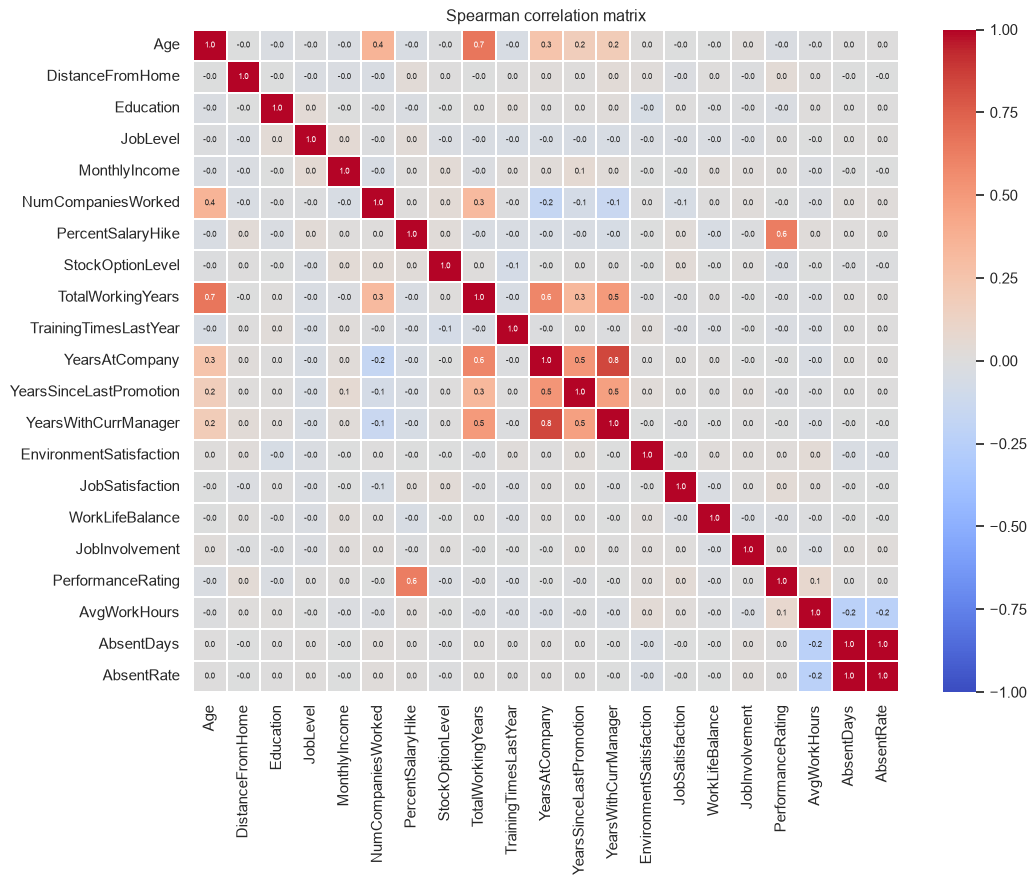

Strongly correlated pairs (|rho| >= 0.5):
        feature_1               feature_2  rho
       AbsentDays              AbsentRate 1.00
   YearsAtCompany    YearsWithCurrManager 0.84
              Age       TotalWorkingYears 0.66
PercentSalaryHike       PerformanceRating 0.63
TotalWorkingYears          YearsAtCompany 0.59
   YearsAtCompany YearsSinceLastPromotion 0.52 



In [61]:
num_cols = [c for c in df.select_dtypes("number").columns if c != "Attrition"]
corr = df[num_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True,
            fmt=".1f", annot_kws={"size": 6}, linewidths=0.3, ax=ax)
ax.set_title("Spearman correlation matrix")
save(fig, "eda_corr.png")

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
         .rename("rho").reset_index())
pairs.columns = ["feature_1", "feature_2", "rho"]
print("Strongly correlated pairs (|rho| >= 0.5):")
print(pairs[pairs["rho"].abs() >= 0.5]
      .sort_values("rho", key=abs, ascending=False).round(2).to_string(index=False), "\n")

### FEATURE SELECTION

In [62]:
FEATURE_GROUPS = {
    "Seniority & pay": ["MonthlyIncome", "JobLevel", "TotalWorkingYears",
                        "YearsAtCompany", "YearsSinceLastPromotion"],
    "Workload & attendance": ["AvgWorkHours", "AbsentRate"],
    "Satisfaction & engagement": ["EnvironmentSatisfaction", "JobSatisfaction",
                                  "WorkLifeBalance", "JobInvolvement"],
    "Commute & travel": ["DistanceFromHome", "BusinessTravel"],
}
FEATURES = [c for cols in FEATURE_GROUPS.values() for c in cols]

# Dropped variables and the reason (for the report)
DROPPED = {
    "EmployeeID / Attrition": "identifier / external-validation label",
    "AbsentDays": "duplicate of AbsentRate (rho = 1.0)",
    "YearsWithCurrManager": "redundant with YearsAtCompany",
    "Age": "redundant with TotalWorkingYears",
    "PerformanceRating": "only values 3/4 (85/15 split), tied to PercentSalaryHike",
    "PercentSalaryHike": "tied to PerformanceRating, no link to the segmentation goal",
    "Education, NumCompaniesWorked, StockOptionLevel, TrainingTimesLastYear":
        "not related to the workload / satisfaction / seniority goals",
    "Department, JobRole, EducationField, MaritalStatus, Gender":
        "nominal: kept for profiling clusters after clustering",
}
print(f"{len(FEATURES)} selected features:")
for g, cols in FEATURE_GROUPS.items():
    print(f"  {g}: {cols}")
print()

13 selected features:
  Seniority & pay: ['MonthlyIncome', 'JobLevel', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion']
  Workload & attendance: ['AvgWorkHours', 'AbsentRate']
  Satisfaction & engagement: ['EnvironmentSatisfaction', 'JobSatisfaction', 'WorkLifeBalance', 'JobInvolvement']
  Commute & travel: ['DistanceFromHome', 'BusinessTravel']



### PREPROCESSING FOR CLUSTERING

#### Encoding

In [63]:
df["BusinessTravel"] = (df["BusinessTravel"].astype(str)
                        .map({"Non-Travel": 0, "Travel_Rarely": 1,
                              "Travel_Frequently": 2}).astype(int))

# One-hot encoding: nominal variables (no order). Not used as clustering
# input; kept to profile clusters later.
NOMINAL = ["Department", "JobRole", "EducationField", "MaritalStatus", "Gender"]
X_nominal = pd.get_dummies(df[NOMINAL].astype(str), dtype=int)

#### Skewness

Skewness before / after log1p:
                         before  after_log1p
MonthlyIncome              1.37         0.29
TotalWorkingYears          1.12        -0.62
YearsAtCompany             1.76        -0.21
YearsSinceLastPromotion    1.98         0.72 



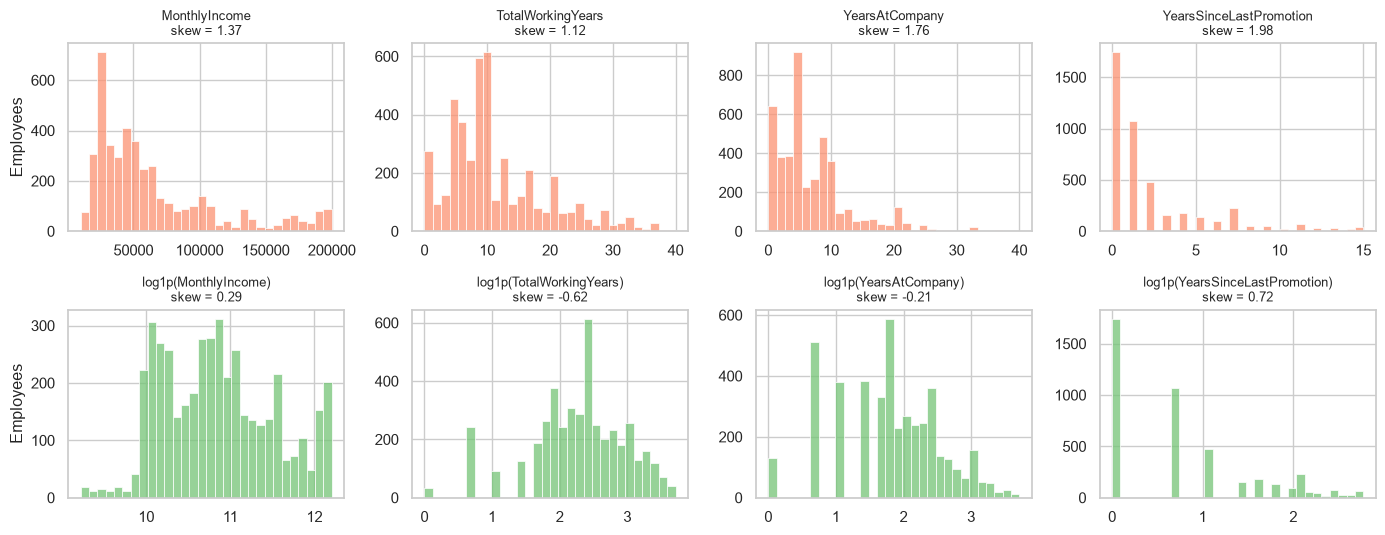

In [64]:
CONTINUOUS = ["MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
              "YearsSinceLastPromotion", "AvgWorkHours", "AbsentRate",
              "DistanceFromHome"]
SKEWED = [c for c in CONTINUOUS if df[c].skew() > 1]

X_raw = df[FEATURES].astype(float).copy()
X_log = X_raw.copy()
X_log[SKEWED] = np.log1p(X_log[SKEWED])

skew_table = pd.DataFrame({"before": X_raw[SKEWED].skew(),
                           "after_log1p": X_log[SKEWED].skew()})
print("Skewness before / after log1p:")
print(skew_table.round(2), "\n")

fig, axes = plt.subplots(2, len(SKEWED), figsize=(14, 5.5))
for j, col in enumerate(SKEWED):
    sns.histplot(X_raw[col], bins=30, color="#fc9272", ax=axes[0, j])
    axes[0, j].set_title(f"{col}\nskew = {X_raw[col].skew():.2f}", fontsize=9)
    sns.histplot(X_log[col], bins=30, color="#74c476", ax=axes[1, j])
    axes[1, j].set_title(f"log1p({col})\nskew = {X_log[col].skew():.2f}", fontsize=9)
    for i in (0, 1):
        axes[i, j].set_xlabel("")
        axes[i, j].set_ylabel("Employees" if j == 0 else "")
save(fig, "prep_skew.png")

#### Scaling

In [65]:
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_log), index=X_log.index, columns=FEATURES)
print("Std of raw features (MonthlyIncome dominates distance-based models):")
print(X_raw.std().round(2).sort_values(ascending=False).head(4).to_string(), "\n")
assert X.isnull().sum().sum() == 0

Std of raw features (MonthlyIncome dominates distance-based models):
MonthlyIncome        47068.89
DistanceFromHome         8.11
TotalWorkingYears        7.77
YearsAtCompany           6.13 



#### Sanity check: effect of scaling and encoding on K-Means

In [66]:
def kmeans_silhouette(M, ks=range(2, 7)):
    return {k: round(silhouette_score(
        M, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(M)), 3)
        for k in ks}

check = pd.DataFrame({
    "raw (no scaling)": kmeans_silhouette(X_raw),
    "log + StandardScaler": kmeans_silhouette(X),
    "scaled + one-hot nominal": kmeans_silhouette(pd.concat([X, X_nominal], axis=1)),
}).T
print("K-Means silhouette by k:")
print(check.to_string(), "\n")

K-Means silhouette by k:
                              2      3      4      5      6
raw (no scaling)          0.708  0.624  0.610  0.617  0.618
log + StandardScaler      0.103  0.082  0.078  0.082  0.080
scaled + one-hot nominal  0.083  0.064  0.061  0.064  0.062 



### DIMENSIONALITY REDUCTION (visualisation)

#### PCA

PC1 = 15.8%, PC2 = 9.8%, PC1+PC2 = 25.6%
Components needed for 90% variance: 11 of 13



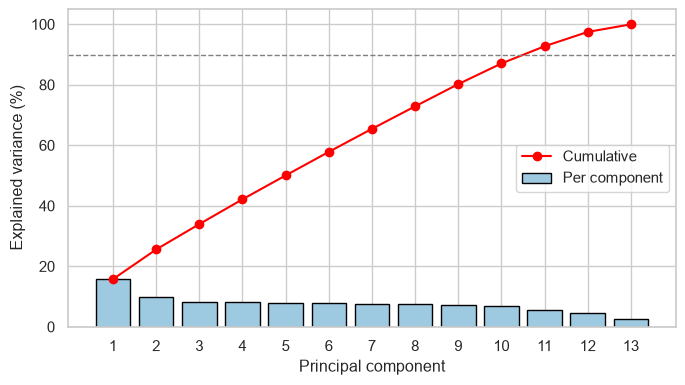

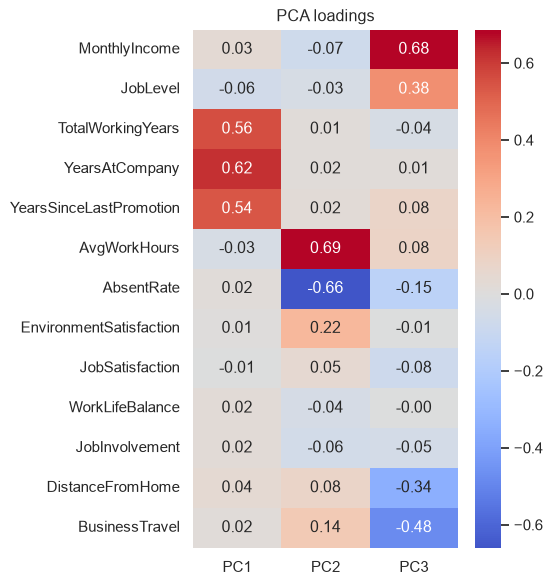

In [67]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca.explained_variance_ratio_
cum = evr.cumsum()
n90 = int(np.argmax(cum >= 0.90)) + 1
print(f"PC1 = {evr[0]:.1%}, PC2 = {evr[1]:.1%}, PC1+PC2 = {cum[1]:.1%}")
print(f"Components needed for 90% variance: {n90} of {len(FEATURES)}\n")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(evr) + 1), evr * 100, color="#9ecae1", edgecolor="black",
       label="Per component")
ax.plot(range(1, len(evr) + 1), cum * 100, "o-", color="red", label="Cumulative")
ax.axhline(90, color="gray", ls="--", lw=1)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance (%)")
ax.set_xticks(range(1, len(evr) + 1))
ax.legend()
save(fig, "pca_scree.png")

X_pca = pd.DataFrame(pca.transform(X), index=X.index,
                     columns=[f"PC{i + 1}" for i in range(len(FEATURES))])

loadings = pd.DataFrame(pca.components_[:3].T, index=FEATURES,
                        columns=["PC1", "PC2", "PC3"])
fig, ax = plt.subplots(figsize=(5.5, 6))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("PCA loadings")
save(fig, "pca_loadings.png")

#### PCA 2D vs t-SNE 2D

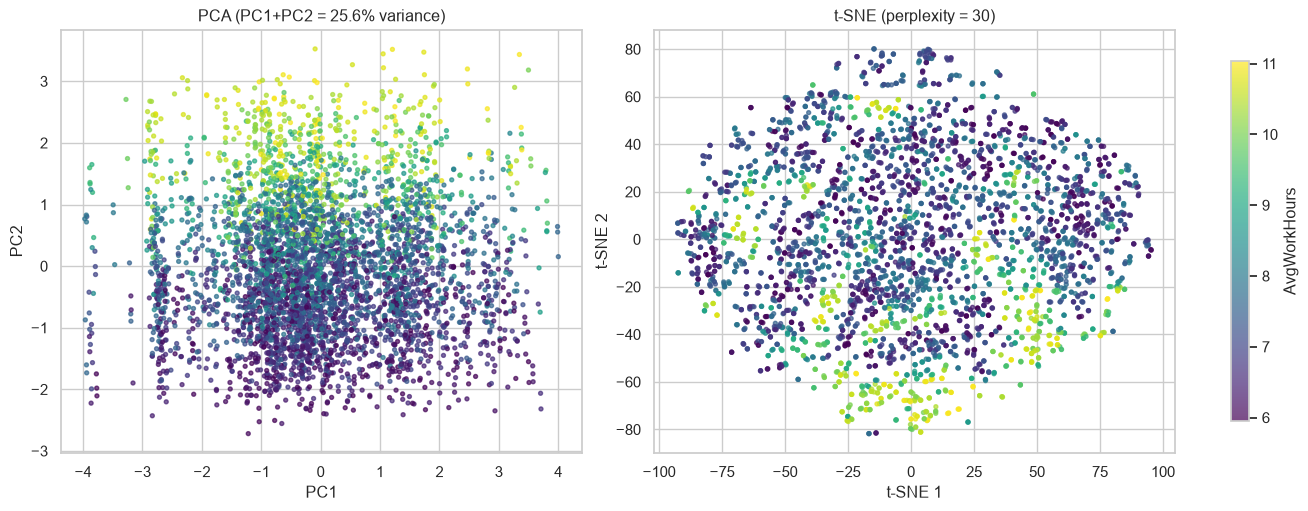

In [68]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
            random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X)

COLOR_BY = "AvgWorkHours"   # colour only for visual reading; not used by the models
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, (xy, title) in zip(axes, [
        (X_pca[["PC1", "PC2"]].values, f"PCA (PC1+PC2 = {cum[1]:.1%} variance)"),
        (X_tsne, "t-SNE (perplexity = 30)")]):
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=df[COLOR_BY], cmap="viridis", s=8, alpha=0.7)
    ax.set_title(title)
fig.colorbar(sc, ax=axes, label=COLOR_BY, shrink=0.85)
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")
save(fig, "embedding_2d.png")

In [69]:
X.head()

,MonthlyIncome,JobLevel,TotalWorkingYears,YearsAtCompany,YearsSinceLastPromotion,AvgWorkHours,AbsentRate,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,DistanceFromHome,BusinessTravel
EmployeeID,,,,,,,,,,,,,
1,1.398738,-0.961486,-2.294803,-1.478408,-0.973342,-0.244123,0.775066,0.252200,1.148864,-1.085336,0.379672,-0.393938,-0.162399
2,-0.319624,-0.961486,-0.499422,-0.026394,-0.117271,0.013564,0.048210,0.252200,-0.666107,1.757749,-1.026167,0.099639,1.717339
3,1.982468,1.749610,-0.720341,-0.026394,-0.973342,-0.513073,-1.042074,-0.665460,-0.666107,-2.506879,0.379672,0.963398,1.717339
4,0.713645,0.845911,0.493953,0.509502,1.594870,-0.378424,0.229924,1.169861,1.148864,0.336206,-1.026167,-0.887515,-2.042138
5,-1.195006,-0.961486,0.011742,0.177344,-0.973342,0.227886,-1.587216,1.169861,-1.573592,0.336206,0.379672,0.099639,-0.162399


# CLUSTERING MODELS

In [72]:
A = X.values
K_RANGE = range(2, 11)


def scores(M, lab):
    """Three internal validity indices for one clustering."""
    return {"silhouette": silhouette_score(M, lab),
            "davies_bouldin": davies_bouldin_score(M, lab),
            "calinski_harabasz": calinski_harabasz_score(M, lab)}

## K-MEANS: Elbow, Silhouette, stability

K-Means model selection:
      inertia  silhouette  davies_bouldin  calinski_harabasz  stability_ARI  inertia_drop_%
k                                                                                          
2   51464.943       0.103           2.716            502.345          0.947             NaN
3   48751.226       0.081           3.046            387.755          0.851           5.273
4   46659.267       0.078           2.848            335.878          0.623           4.291
5   44709.186       0.082           2.666            310.869          0.816           4.179
6   43144.688       0.080           2.570            289.595          0.704           3.499
7   41836.795       0.075           2.458            271.757          0.787           3.031
8   40806.339       0.078           2.338            254.644          0.683           2.463
9   39982.384       0.074           2.251            238.690          0.602           2.019
10  39297.796       0.066           2.413            22

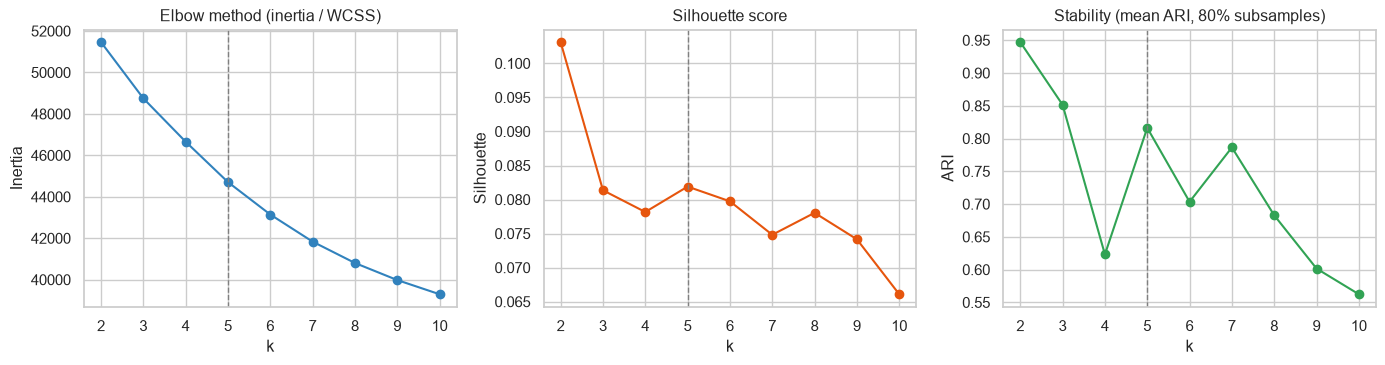

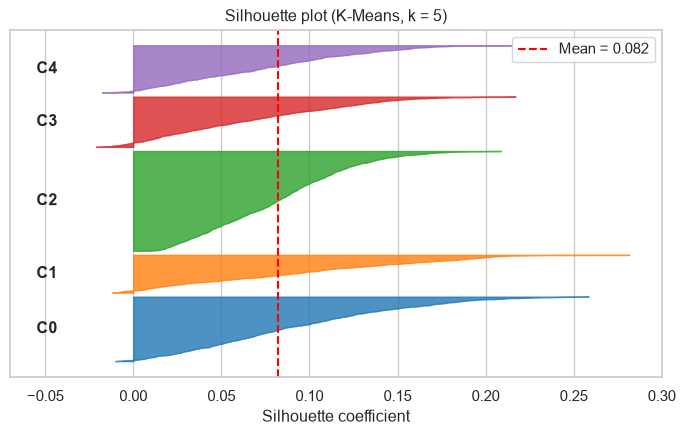

Cluster sizes (K-Means): [949, 556, 1469, 740, 696] | share of negative silhouette: 3.2%



In [73]:
def kmeans_stability(M, k, n_runs=10, frac=0.8):
    """Mean ARI between K-Means fitted on random 80% subsamples
    (every model then labels all employees)."""
    rng = np.random.RandomState(RANDOM_STATE)
    labs = []
    for b in range(n_runs):
        idx = rng.choice(len(M), int(frac * len(M)), replace=False)
        labs.append(KMeans(k, n_init=10, random_state=b).fit(M[idx]).predict(M))
    return np.mean([adjusted_rand_score(labs[i], labs[j])
                    for i in range(n_runs) for j in range(i + 1, n_runs)])


rows = []
for k in K_RANGE:
    km = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit(A)
    rows.append({"k": k, "inertia": km.inertia_, **scores(A, km.labels_),
                 "stability_ARI": kmeans_stability(A, k)})
km_table = pd.DataFrame(rows).set_index("k")
km_table["inertia_drop_%"] = -km_table["inertia"].pct_change() * 100
print("K-Means model selection:")
print(km_table.round(3).to_string(), "\n")

# Choice of K: k = 2 only separates tenure (see Report), so the search starts
# at k = 3 and takes the highest silhouette in 3..8.
K_FINAL = int(km_table.loc[3:8, "silhouette"].idxmax())
print(f"K_FINAL = {K_FINAL}\n")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(km_table.index, km_table["inertia"], "o-", color="#3182bd")
axes[0].set(title="Elbow method (inertia / WCSS)", xlabel="k", ylabel="Inertia")
axes[1].plot(km_table.index, km_table["silhouette"], "o-", color="#e6550d")
axes[1].set(title="Silhouette score", xlabel="k", ylabel="Silhouette")
axes[2].plot(km_table.index, km_table["stability_ARI"], "o-", color="#31a354")
axes[2].set(title="Stability (mean ARI, 80% subsamples)", xlabel="k", ylabel="ARI")
for ax in axes:
    ax.axvline(K_FINAL, color="gray", ls="--", lw=1)
    ax.set_xticks(list(K_RANGE))
save(fig, "km_selection.png")

km = KMeans(K_FINAL, n_init=20, random_state=RANDOM_STATE).fit(A)
labels = pd.DataFrame(index=X.index)
labels["KMeans"] = km.labels_

# Silhouette plot of every employee for the chosen K
sil = silhouette_samples(A, km.labels_)
fig, ax = plt.subplots(figsize=(7, 4.5))
y0 = 0
for c in range(K_FINAL):
    s = np.sort(sil[km.labels_ == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, alpha=0.8,
                     color=plt.cm.tab10(c))
    ax.text(-0.055, y0 + len(s) / 2, f"C{c}", va="center", fontweight="bold")
    y0 += len(s) + 60
ax.axvline(sil.mean(), color="red", ls="--", label=f"Mean = {sil.mean():.3f}")
ax.set(title=f"Silhouette plot (K-Means, k = {K_FINAL})",
       xlabel="Silhouette coefficient", yticks=[], xlim=(-0.07, 0.3))
ax.legend()
save(fig, "km_silhouette_plot.png")
print("Cluster sizes (K-Means):", np.bincount(km.labels_).tolist(),
      "| share of negative silhouette: "
      f"{(sil < 0).mean():.1%}\n")

## HIERARCHICAL CLUSTERING (Ward) + DENDROGRAM

Ward model selection:
    silhouette  davies_bouldin  calinski_harabasz
k                                                
2        0.073           2.976            319.346
3        0.062           3.378            263.481
4        0.045           3.543            235.781
5        0.047           3.240            218.631
6        0.048           3.060            204.597
7        0.047           2.976            192.632
8        0.044           2.989            184.611
9        0.043           2.861            177.717
10       0.038           2.711            169.453 



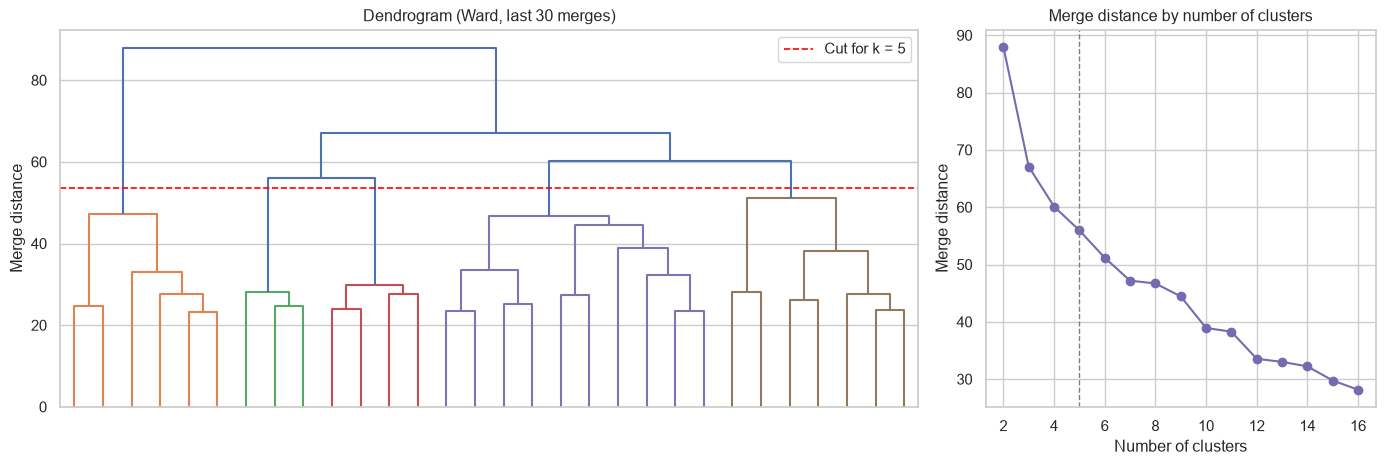

ARI between K-Means and Ward (k = 5): 0.344
Cluster sizes (Ward): [989, 451, 434, 1576, 960] 



In [74]:
Z = linkage(A, method="ward")

ward_rows = []
for k in K_RANGE:
    lab = fcluster(Z, k, criterion="maxclust") - 1
    ward_rows.append({"k": k, **scores(A, lab)})
ward_table = pd.DataFrame(ward_rows).set_index("k")
print("Ward model selection:")
print(ward_table.round(3).to_string(), "\n")

labels["Ward"] = fcluster(Z, K_FINAL, criterion="maxclust") - 1
cut_height = (Z[-(K_FINAL - 1), 2] + Z[-K_FINAL, 2]) / 2   # between k and k-1 merges

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=cut_height,
           no_labels=True, ax=axes[0])
axes[0].axhline(cut_height, color="red", ls="--", lw=1.2,
                label=f"Cut for k = {K_FINAL}")
axes[0].set(title="Dendrogram (Ward, last 30 merges)", ylabel="Merge distance")
axes[0].legend()
heights = Z[-15:, 2][::-1]
axes[1].plot(range(2, 17), heights, "o-", color="#756bb1")
axes[1].axvline(K_FINAL, color="gray", ls="--", lw=1)
axes[1].set(title="Merge distance by number of clusters", xlabel="Number of clusters",
            ylabel="Merge distance")
save(fig, "dendrogram_ward.png")

ari_km_ward = adjusted_rand_score(labels["KMeans"], labels["Ward"])
print(f"ARI between K-Means and Ward (k = {K_FINAL}): {ari_km_ward:.3f}")
print("Cluster sizes (Ward):", np.bincount(labels["Ward"]).tolist(), "\n")

## DBSCAN: density clusters and anomalies

DBSCAN sensitivity (min_samples = 26):
     clusters  noise  noise_%
eps                          
2.6         1    927     21.0
2.8         1    348      7.9
3.0         1    105      2.4
3.2         1     33      0.7
3.4         1      4      0.1 

DBSCAN (eps = 3.0): 1 cluster(s), 105 anomalies (2.4%)


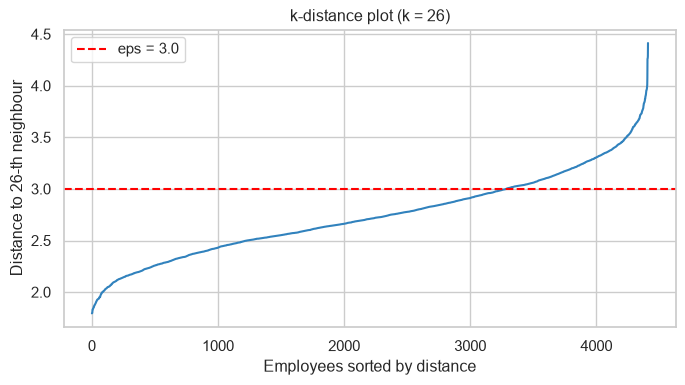

Mean z-score of anomalies:
WorkLifeBalance           -0.87
YearsAtCompany            -0.55
JobInvolvement            -0.48
TotalWorkingYears         -0.40
YearsSinceLastPromotion   -0.40
AbsentRate                -0.20
BusinessTravel            -0.11
JobSatisfaction            0.05
EnvironmentSatisfaction    0.12
DistanceFromHome           0.65
MonthlyIncome              0.69
AvgWorkHours               0.87
JobLevel                   0.94
Attrition rate: anomalies 36.2% vs rest 15.6%



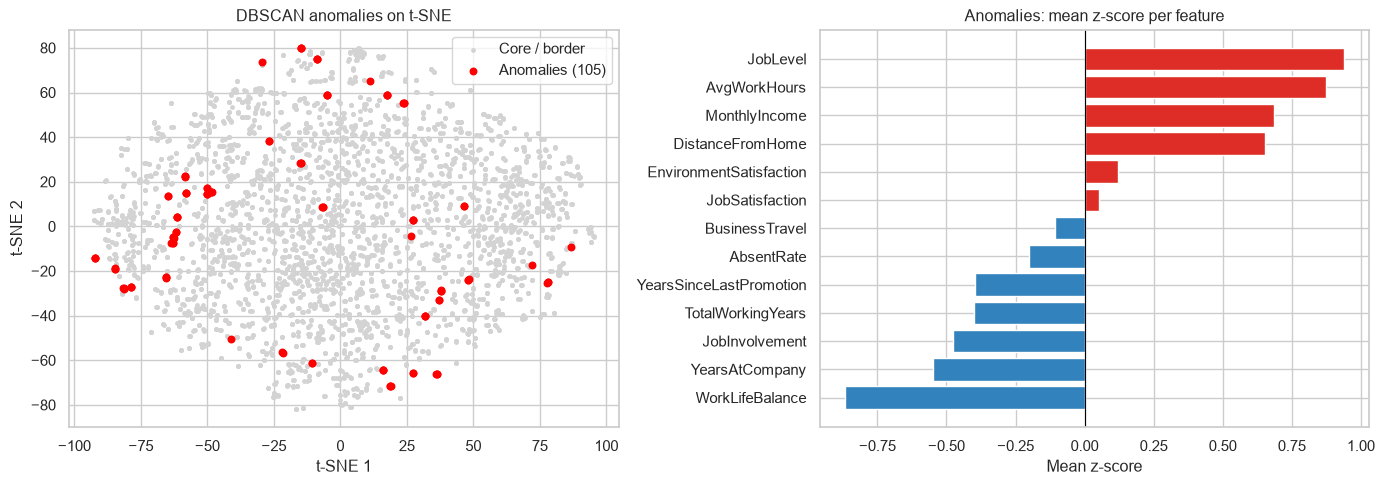

In [75]:
MIN_SAMPLES = 2 * A.shape[1]          # common rule: 2 x number of features
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(A)
                .kneighbors(A)[0][:, -1])

sens = []
for eps in (2.6, 2.8, 3.0, 3.2, 3.4):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(A)
    sens.append({"eps": eps, "clusters": len(set(lab) - {-1}),
                 "noise": int((lab == -1).sum()),
                 "noise_%": (lab == -1).mean() * 100})
sens = pd.DataFrame(sens).set_index("eps")
print(f"DBSCAN sensitivity (min_samples = {MIN_SAMPLES}):")
print(sens.round(1).to_string(), "\n")

EPS = 3.0     # flags about 2-3% of employees as anomalies
labels["DBSCAN"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(A)
is_anom = (labels["DBSCAN"] == -1).values
n_cl = len(set(labels["DBSCAN"]) - {-1})
print(f"DBSCAN (eps = {EPS}): {n_cl} cluster(s), {is_anom.sum()} anomalies "
      f"({is_anom.mean():.1%})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(kdist, color="#3182bd")
ax.axhline(EPS, color="red", ls="--", label=f"eps = {EPS}")
ax.set(title=f"k-distance plot (k = {MIN_SAMPLES})", xlabel="Employees sorted by distance",
       ylabel=f"Distance to {MIN_SAMPLES}-th neighbour")
ax.legend()
save(fig, "dbscan_kdist.png")

# Who are the anomalies? (mean z-score vs. the rest, plus external Attrition check)
anom_profile = X[is_anom].mean().sort_values()
attr_anom, attr_rest = df.loc[is_anom, "Attrition"].mean(), df.loc[~is_anom, "Attrition"].mean()
print("Mean z-score of anomalies:")
print(anom_profile.round(2).to_string())
print(f"Attrition rate: anomalies {attr_anom:.1%} vs rest {attr_rest:.1%}\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_tsne[~is_anom, 0], X_tsne[~is_anom, 1], s=6, c="lightgray", label="Core / border")
axes[0].scatter(X_tsne[is_anom, 0], X_tsne[is_anom, 1], s=22, c="red", label=f"Anomalies ({is_anom.sum()})")
axes[0].set(title="DBSCAN anomalies on t-SNE", xlabel="t-SNE 1", ylabel="t-SNE 2")
axes[0].legend()
colors = ["#de2d26" if v > 0 else "#3182bd" for v in anom_profile.values]
axes[1].barh(anom_profile.index, anom_profile.values, color=colors)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(title="Anomalies: mean z-score per feature", xlabel="Mean z-score")
save(fig, "dbscan_anomalies.png")

## K-MEANS CLUSTERS ON PCA / t-SNE

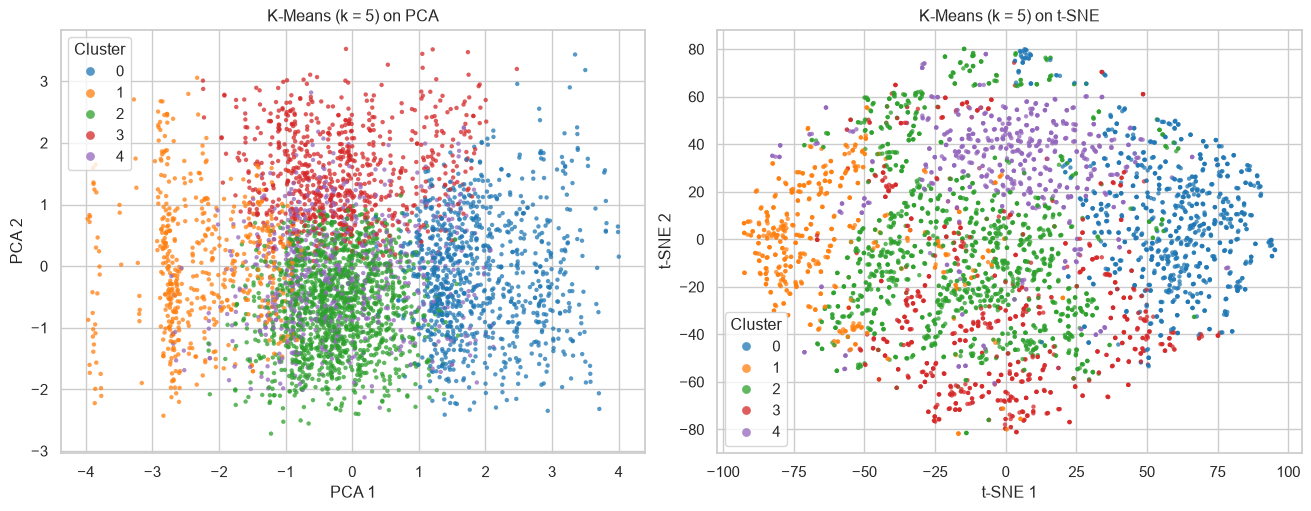

,KMeans,Ward,DBSCAN
EmployeeID,,,
1,1,4,0
2,2,4,0
3,4,2,-1
4,0,0,0
5,3,3,0


In [76]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, xy, name in [(axes[0], X_pca[["PC1", "PC2"]].values, "PCA"),
                     (axes[1], X_tsne, "t-SNE")]:
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=labels["KMeans"].values,
                    palette="tab10", s=10, alpha=0.75, linewidth=0, ax=ax)
    ax.set(title=f"K-Means (k = {K_FINAL}) on {name}", xlabel=f"{name} 1", ylabel=f"{name} 2")
    ax.legend(title="Cluster", markerscale=2)
save(fig, "clusters_2d.png")

labels.to_csv("cluster_labels.csv")
labels.head()